# Predicción de la pobreza por ingresos en hogares mexicanos (ENIGH 2016–2020) con aprendizaje automático

**Objetivo.** Clasificar si un hogar se encuentra por debajo de la línea de pobreza por ingresos (`plp = 1`) a partir de sus características sociodemográficas, de seguridad alimentaria, de vivienda y de equipamiento, **sin usar el ingreso** como predictor.

**Modelos comparados (7):**
1. Red neuronal totalmente conectada (FCNN) 128‑64‑32‑16‑1 (Keras/TensorFlow)
2. Random Forest
3. Regresión logística
4. Perceptrón multicapa (MLP, scikit‑learn)
5. Perceptrón simple (clásico) y perceptrón promediado (*averaged perceptron*)
6. XGBoost
7. Gradient Boosting (implementación por histogramas de scikit‑learn, `HistGradientBoostingClassifier`)

**Mejoras respecto al flujo original**

| # | Flujo original | Flujo mejorado | Motivo |
|---|---|---|---|
| 1 | Se eliminaban 5 838 filas con nulos | Imputación (mediana / moda) ajustada solo con entrenamiento + indicador de nulo | Conservar información y evitar sesgo de selección |
| 2 | Sin escalado | `StandardScaler` para variables numéricas | Recomendado para modelos entrenados por gradiente (redes neuronales, regresión logística) |
| 3 | División aleatoria 80/20 sin estratificar | División estratificada 80/20 + 10 % de validación interna | Mantener la proporción de clases y permitir *early stopping* |
| 4 | Hiperparámetros por defecto | Búsqueda aleatoria con validación cruzada estratificada (3 pliegues) | Ajuste sistemático y reproducible |
| 5 | Variables originales | Ingeniería de características (hacinamiento, dependencia, índice de bienes, etc.) | Capturar relaciones de dominio |
| 6 | Escolaridad en *one‑hot* | Escolaridad como variable ordinal | Respeta el orden natural de los niveles educativos |
| 7 | Accuracy, precisión, recall, F1 | + ROC‑AUC, MCC, IC 95 % por *bootstrap* y prueba de McNemar | Evaluación más robusta y comparación estadística |
| 8 | FCNN 128‑64‑32 sin regularización | FCNN 128‑64‑32‑16‑1 con BatchNorm, Dropout, L2, *early stopping* | Mejor generalización |
| 9 | Perceptrón clásico | + Perceptrón promediado | El perceptrón clásico es inestable con datos no separables linealmente |

**Cómo reproducir en Google Colab:** ejecute las celdas en orden (`Entorno de ejecución → Ejecutar todas`). Ajuste únicamente la variable `RUTA_DATOS` de la sección 2. El tiempo total aproximado es de 30–60 min en un entorno de CPU estándar; puede reducirlo con `MODO_RAPIDO = True`.

## Índice
1. Configuración del entorno
2. Carga de datos
3. Integración y validación de los datos
4. Análisis exploratorio
5. Definición del problema y selección de variables
6. Ingeniería de características
7. División de los datos
8. Preprocesamiento
9. Funciones de evaluación
10. Ajuste de hiperparámetros
11. Entrenamiento y evaluación de los siete modelos
12. Comparación de modelos y pruebas estadísticas
13. Visualizaciones
14. Estudio de ablación (efecto de cada mejora)
15. Interpretabilidad: importancia por permutación
16. Exportación de resultados
17. Conclusiones

## 1. Configuración del entorno

In [1]:
# En Colab, scikit-learn, XGBoost y TensorFlow ya vienen instalados.
# Si alguna librería faltara, descomente la siguiente línea:
# !pip install -q xgboost

In [2]:
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix,
                             classification_report, roc_curve)
from scipy.stats import chi2, loguniform, uniform, randint
import xgboost as xgb
import sklearn

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

# ---------------- Reproducibilidad ----------------
SEMILLA = 42
np.random.seed(SEMILLA)
keras.utils.set_random_seed(SEMILLA)

# ---------------- Parámetros globales ----------------
MODO_RAPIDO = False          # True: búsquedas más pequeñas (útil para pruebas)
N_MUESTRA_BUSQUEDA = 30_000 if MODO_RAPIDO else 60_000   # tamaño de la submuestra para tuning
CARPETA_SALIDA = "resultados_pobreza"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgb.__version__,
      "| TensorFlow:", tf.__version__, "| pandas:", pd.__version__)

I0000 00:00:1793920687.493185     202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


scikit-learn: 1.9.1 | XGBoost: 3.4.1 | TensorFlow: 2.21.0 | pandas: 3.0.6


I0000 00:00:1793920688.770390     202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Carga de datos
Los archivos `base2016.xlsx`, `base2018.xlsx` y `base2020.xlsx` provienen de la Encuesta Nacional de Ingresos y Gastos de los Hogares (ENIGH) del INEGI. Cada registro corresponde a un **hogar**.

In [3]:
# Montar Google Drive solo si se ejecuta en Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_DATOS = "/content/drive/Shareddrives/PLANEACIÓN DE MATERIAS/MCI_I2026_MINERÍA DE DATOS/DATASETS/"
except ImportError:
    # Ejecución local: ajuste la ruta o defina la variable de entorno RUTA_DATOS
    RUTA_DATOS = os.environ.get("RUTA_DATOS", "./")

def leer_datos(ruta):
    # La primera columna del Excel es un índice sin significado
    return pd.read_excel(ruta, sheet_name="Sheet1", index_col=0)

ANIOS = [2016, 2018, 2020]
bases = {a: leer_datos(os.path.join(RUTA_DATOS, f"base{a}.xlsx")) for a in ANIOS}
for a, d in bases.items():
    print(f"ENIGH {a}: {d.shape[0]:,} hogares, {d.shape[1]} columnas")

ENIGH 2016: 70,311 hogares, 34 columnas
ENIGH 2018: 74,647 hogares, 34 columnas
ENIGH 2020: 89,006 hogares, 34 columnas


## 3. Integración y validación de los datos

In [4]:
# Verificar que las tres bases tengan exactamente las mismas columnas
columnas_ref = list(bases[2016].columns)
assert all(list(d.columns) == columnas_ref for d in bases.values()), "Las bases no tienen las mismas columnas"

for a, d in bases.items():
    d["anio"] = a
df = pd.concat(bases.values(), axis=0, ignore_index=True)
print("Registros totales:", f"{len(df):,}")
print("Hogares duplicados (sin considerar folios):",
      df.drop(columns=["folioviv", "foliohog"]).duplicated().sum())
df.head()

Registros totales: 233,964
Hogares duplicados (sin considerar folios): 0


,folioviv,foliohog,plp,plp_e,ictpc,entidad,rur_urb,mujer_jefe_hog,escolaridad_educacion_jh,tot_trab,recibe_ayuda_apoyo_gub,edad_jefe,tot_integ,prog_soc_porcent,escala_elcsa,acc_alim_preocupo,acc_alim_sin_alim,acc_alim_no_alim_sal,acc_alim_poca_var,acc_alim_no_come,acc_alim_come_menos,acc_alim_hambre,acc_alim_no_come_dia,auto_camioneta_van,conex_inte,compu,lavad,equip_tel_fijo,refri,hindig,discap,tot_integ_0_17,num_cuarto,bano_comp,anio
0,100003801,1,0,0,17191.509772,1,0,0,10,2,0,33,2,0.0,2,1,0,1,1,0,0,0,1,1,1,1,1.0,0,1.0,0,0,0,5,1.0,2016
1,100003802,1,0,0,24891.201922,1,0,0,10,2,0,29,2,0.0,0,0,0,0,0,0,0,0,0,1,0,0,1.0,0,1.0,0,0,0,5,1.0,2016
2,100003803,1,0,0,5713.706100,1,0,0,10,1,0,47,6,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,1,1.0,0,0,4,8,2.0,2016
3,100003804,1,0,0,6630.419310,1,0,1,11,2,0,29,3,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,0,1.0,0,0,0,5,2.0,2016
4,100003805,1,0,0,7227.184554,1,0,0,10,1,0,55,2,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,1,1.0,0,0,0,6,2.0,2016


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 233964 entries, 0 to 233963
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   folioviv                  233964 non-null  int64  
 1   foliohog                  233964 non-null  int64  
 2   plp                       233964 non-null  int64  
 3   plp_e                     233964 non-null  int64  
 4   ictpc                     233964 non-null  float64
 5   entidad                   233964 non-null  int64  
 6   rur_urb                   233964 non-null  int64  
 7   mujer_jefe_hog            233964 non-null  int64  
 8   escolaridad_educacion_jh  233964 non-null  int64  
 9   tot_trab                  233964 non-null  int64  
 10  recibe_ayuda_apoyo_gub    233964 non-null  int64  
 11  edad_jefe                 233964 non-null  int64  
 12  tot_integ                 233964 non-null  int64  
 13  prog_soc_porcent          233937 non-null  float64
 14 

## 4. Análisis exploratorio

In [6]:
# 4.1 Valores faltantes
nulos = df.isna().sum()
display(nulos[nulos > 0].to_frame("n_nulos").assign(porcentaje=lambda t: 100 * t.n_nulos / len(df)))

,n_nulos,porcentaje
prog_soc_porcent,27,0.011540
lavad,1,0.000427
refri,1,0.000427
bano_comp,5810,2.483288


In [7]:
# 4.2 Balance de clases de las posibles variables objetivo
balance = pd.DataFrame({
    "No pobre (0)": [df.plp.eq(0).sum(), df.plp_e.eq(0).sum()],
    "Pobre (1)":    [df.plp.eq(1).sum(), df.plp_e.eq(1).sum()]},
    index=["plp (pobreza por ingresos)", "plp_e (pobreza extrema por ingresos)"])
balance["% clase 1"] = 100 * balance["Pobre (1)"] / balance.sum(axis=1)
display(balance)

# Prevalencia de pobreza por año y tipo de localidad (rur_urb = 1: rural)
display((100 * df.groupby(["anio", "rur_urb"]).plp.mean()).unstack().round(2)
        .rename(columns={0: "% pobres urbano", 1: "% pobres rural"}))

,No pobre (0),Pobre (1),% clase 1
plp (pobreza por ingresos),132594,101370,43.327179
plp_e (pobreza extrema por ingresos),204500,29464,12.593390


rur_urb,% pobres urbano,% pobres rural
anio,,
2016,41.10,47.14
2018,40.28,46.57
2020,43.01,45.34


In [8]:
# 4.3 Verificación de la variable escala_elcsa: es una función exacta de las 8 preguntas de acceso a la alimentación
ALIM = ["acc_alim_preocupo", "acc_alim_sin_alim", "acc_alim_no_alim_sal", "acc_alim_poca_var",
        "acc_alim_no_come", "acc_alim_come_menos", "acc_alim_hambre", "acc_alim_no_come_dia"]
suma = df[ALIM].sum(axis=1)
elcsa_calc = np.select([suma == 0, suma <= 3, suma <= 6], [0, 1, 2], 3)
print("Coincidencia escala_elcsa calculada vs. registrada:", f"{(elcsa_calc == df.escala_elcsa).mean():.2%}")

Coincidencia escala_elcsa calculada vs. registrada: 100.00%


In [9]:
# 4.4 Verificación de fuga de información: plp se obtiene comparando ictpc con la línea de pobreza
# del año y tipo de localidad. Si ictpc se usara como predictor, el problema sería trivial.
umbrales = df.groupby(["anio", "rur_urb", "plp"]).ictpc.agg(["min", "max"]).round(1)
display(umbrales)

min        max
anio rur_urb plp                   
2016 0       0    2045.3  1918799.8
             1       0.0     2903.7
     1       0    2030.2   301092.2
             1       0.0     2030.0
2018 0       0    2441.1   278164.8
             1       0.0     3325.3
     1       0    2316.6   771619.8
             1       0.0     2316.0
2020 0       0    2525.5  2182944.0
             1       0.0     3559.7
     1       0    2520.6   780927.3
             1       0.0     2520.1

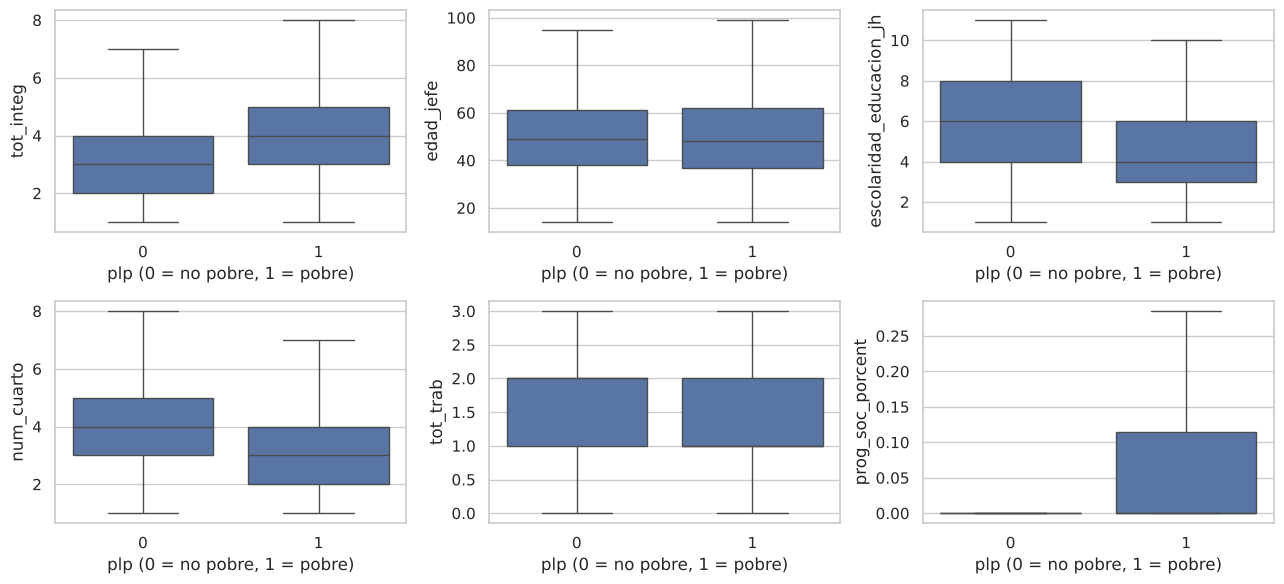

In [10]:
# 4.5 Distribución de algunas variables numéricas por clase
num_vis = ["tot_integ", "edad_jefe", "escolaridad_educacion_jh", "num_cuarto", "tot_trab", "prog_soc_porcent"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a_, c in zip(ax.ravel(), num_vis):
    sns.boxplot(data=df, x="plp", y=c, ax=a_, showfliers=False)
    a_.set_xlabel("plp (0 = no pobre, 1 = pobre)")
plt.tight_layout(); plt.show()

## 5. Definición del problema y selección de variables
* **Variable objetivo:** `plp` (1 = hogar con ingreso per cápita por debajo de la línea de pobreza por ingresos). Presenta un balance razonable (≈43 % de clase 1).
* `plp_e` no se usa como objetivo en este estudio: su clase positiva representa solo ≈12.6 % de los hogares, por lo que requeriría un tratamiento específico de desbalance; queda como trabajo futuro.
* **Variables excluidas:**
  * `folioviv`, `foliohog`: identificadores sin valor predictivo.
  * `ictpc`, `plp_e`: **fuga de información** (la etiqueta se deriva directamente del ingreso).
  * `escala_elcsa`: redundante (combinación exacta de las 8 variables `acc_alim_*`, verificado en 4.3).

In [11]:
OBJETIVO = "plp"
EXCLUIR = ["folioviv", "foliohog", "ictpc", "plp_e", "escala_elcsa"]
y = df[OBJETIVO].astype(int).values
X_raw = df.drop(columns=EXCLUIR + [OBJETIVO])
print("Predictores originales:", X_raw.shape[1])
print(list(X_raw.columns))

Predictores originales: 29
['entidad', 'rur_urb', 'mujer_jefe_hog', 'escolaridad_educacion_jh', 'tot_trab', 'recibe_ayuda_apoyo_gub', 'edad_jefe', 'tot_integ', 'prog_soc_porcent', 'acc_alim_preocupo', 'acc_alim_sin_alim', 'acc_alim_no_alim_sal', 'acc_alim_poca_var', 'acc_alim_no_come', 'acc_alim_come_menos', 'acc_alim_hambre', 'acc_alim_no_come_dia', 'auto_camioneta_van', 'conex_inte', 'compu', 'lavad', 'equip_tel_fijo', 'refri', 'hindig', 'discap', 'tot_integ_0_17', 'num_cuarto', 'bano_comp', 'anio']


## 6. Ingeniería de características
Se crean variables derivadas, calculadas **fila por fila** (no usan información de otros hogares, por lo que no generan fuga):

| Variable | Definición | Interpretación |
|---|---|---|
| `tasa_dependencia` | `tot_integ_0_17 / tot_integ` | Proporción de menores en el hogar |
| `trab_por_integ` | `tot_trab / tot_integ` | Integrantes ocupados por persona |
| `hacinamiento` | `tot_integ / num_cuarto` | Personas por cuarto |
| `integ_por_bano` | `tot_integ / (bano_comp + 1)` | Presión sobre servicios sanitarios |
| `inseg_alim_suma` | suma de las 8 `acc_alim_*` | Intensidad de inseguridad alimentaria |
| `indice_bienes` | suma de 6 bienes durables | Índice simple de activos del hogar |
| `sin_trabajador` | `tot_trab == 0` | Hogar sin ingreso laboral |
| `bano_comp_nulo` | `bano_comp` faltante | Indicador de dato faltante |

In [12]:
BIENES = ["auto_camioneta_van", "conex_inte", "compu", "lavad", "equip_tel_fijo", "refri"]

def ingenieria_caracteristicas(X):
    X = X.copy()
    X["bano_comp_nulo"]   = X["bano_comp"].isna().astype(int)
    X["tasa_dependencia"] = X["tot_integ_0_17"] / X["tot_integ"]
    X["trab_por_integ"]   = X["tot_trab"] / X["tot_integ"]
    X["hacinamiento"]     = X["tot_integ"] / X["num_cuarto"].clip(lower=1)
    X["integ_por_bano"]   = X["tot_integ"] / (X["bano_comp"].fillna(0) + 1)
    X["inseg_alim_suma"]  = X[ALIM].sum(axis=1)
    X["indice_bienes"]    = X[BIENES].sum(axis=1, min_count=1)
    X["sin_trabajador"]   = (X["tot_trab"] == 0).astype(int)
    return X

X = ingenieria_caracteristicas(X_raw)
print("Predictores tras la ingeniería de características:", X.shape[1])

Predictores tras la ingeniería de características: 37


## 7. División de los datos
* 80 % entrenamiento / 20 % prueba, **estratificada** por `plp`.
* Del entrenamiento se reserva un 10 % estratificado como **validación** para el *early stopping* de XGBoost y de la FCNN.
* El conjunto de prueba **no se utiliza** en ninguna decisión de entrenamiento ni de ajuste.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEMILLA)

resumen_div = pd.DataFrame({
    "n": [len(X_train), len(X_tr), len(X_val), len(X_test)],
    "% pobres": [100*y_train.mean(), 100*y_tr.mean(), 100*y_val.mean(), 100*y_test.mean()]},
    index=["Entrenamiento completo", "  - Sub-entrenamiento", "  - Validación", "Prueba"]).round(2)
display(resumen_div)

,n,% pobres
Entrenamiento completo,187171,43.33
- Sub-entrenamiento,168453,43.33
- Validación,18718,43.33
Prueba,46793,43.33


## 8. Preprocesamiento
`ColumnTransformer` ajustado **solo con datos de entrenamiento**:
* **Numéricas** (incluye escolaridad ordinal y variables derivadas): imputación por mediana + `StandardScaler`.
* **Binarias:** imputación por moda (sin escalar).
* **Categóricas nominales** (`entidad`, `anio`): `OneHotEncoder`.

In [14]:
CAT = ["entidad", "anio"]
BIN = ["rur_urb", "mujer_jefe_hog", "recibe_ayuda_apoyo_gub"] + ALIM + BIENES + \
      ["hindig", "discap", "bano_comp_nulo", "sin_trabajador"]
NUM = [c for c in X.columns if c not in CAT + BIN]
print("Numéricas:", NUM, "\nBinarias:", len(BIN), "| Categóricas:", CAT)

def crear_preprocesador(escalar=True):
    pasos_num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("esc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), NUM),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

pre = crear_preprocesador().fit(X_train)          # para modelos ajustados con todo el entrenamiento
pre_tr = crear_preprocesador().fit(X_tr)          # para modelos con validación (XGBoost, FCNN)

Xt_train, Xt_test = pre.transform(X_train), pre.transform(X_test)
Xs_tr, Xs_val, Xs_test = pre_tr.transform(X_tr), pre_tr.transform(X_val), pre_tr.transform(X_test)
nombres_finales = pre.get_feature_names_out()
print("Dimensión de la matriz final:", Xt_train.shape)

Numéricas: ['escolaridad_educacion_jh', 'tot_trab', 'edad_jefe', 'tot_integ', 'prog_soc_porcent', 'tot_integ_0_17', 'num_cuarto', 'bano_comp', 'tasa_dependencia', 'trab_por_integ', 'hacinamiento', 'integ_por_bano', 'inseg_alim_suma', 'indice_bienes'] 
Binarias: 21 | Categóricas: ['entidad', 'anio']


Dimensión de la matriz final: (187171, 70)


## 9. Funciones de evaluación

In [15]:
resultados, predicciones, tiempos = [], {}, {}

def evaluar(nombre, y_true, puntaje, pred):
    # puntaje: probabilidad o función de decisión (para ROC-AUC); pred: clase predicha
    rep = classification_report(y_true, pred, digits=4, output_dict=True)
    fila = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": rep["weighted avg"]["precision"],
        "Recall": rep["weighted avg"]["recall"],
        "F1-score": rep["weighted avg"]["f1-score"],
        "Precision (pobre)": rep["1"]["precision"],
        "Recall (pobre)": rep["1"]["recall"],
        "F1 (pobre)": rep["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_true, puntaje),
        "MCC": matthews_corrcoef(y_true, pred)}
    print(f"\n===== {nombre} =====")
    print(classification_report(y_true, pred, digits=4, target_names=["No pobre", "Pobre"]))
    print(f"ROC-AUC: {fila['ROC-AUC']:.4f} | MCC: {fila['MCC']:.4f}")
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(4, 3.2))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["No pobre", "Pobre"], yticklabels=["No pobre", "Pobre"])
    plt.title(f"Matriz de confusión – {nombre}"); plt.xlabel("Predicción"); plt.ylabel("Real")
    plt.tight_layout(); plt.show()
    return fila

def registrar(nombre, puntaje, pred, t):
    predicciones[nombre] = {"puntaje": np.asarray(puntaje), "pred": np.asarray(pred)}
    tiempos[nombre] = t
    resultados.append(evaluar(nombre, y_test, puntaje, pred) | {"Tiempo (s)": t})

## 10. Ajuste de hiperparámetros
Se usa `RandomizedSearchCV` (búsqueda aleatoria) con validación cruzada estratificada de 3 pliegues sobre una submuestra estratificada del entrenamiento (60 000 hogares) para acotar el costo de cómputo. La métrica de selección es *accuracy*. Los mejores hiperparámetros se reentrenan después con todo el conjunto de entrenamiento.

In [16]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
idx_bus, _ = train_test_split(np.arange(len(y_train)), train_size=N_MUESTRA_BUSQUEDA,
                              stratify=y_train, random_state=SEMILLA)
Xb, yb = Xt_train[idx_bus], y_train[idx_bus]

def buscar(nombre, estimador, espacio, n_iter):
    t0 = time.time()
    bus = RandomizedSearchCV(estimador, espacio, n_iter=n_iter, scoring="accuracy", cv=cv3,
                             random_state=SEMILLA, n_jobs=-1, refit=False)
    bus.fit(Xb, yb)
    print(f"{nombre}: mejor accuracy CV = {bus.best_score_:.4f} ({time.time()-t0:.0f} s)")
    print("  Mejores hiperparámetros:", bus.best_params_)
    return bus.best_params_

mejores = {}

In [17]:
import json
with open(os.path.join(CARPETA_SALIDA, "mejores_hiperparametros.json")) as f:
    mejores = json.load(f)
mejores["Perceptrón multicapa"]["hidden_layer_sizes"] = tuple(mejores["Perceptrón multicapa"]["hidden_layer_sizes"])

In [18]:
mejores["Perceptrón"] = buscar(
    "Perceptrón", Perceptron(random_state=SEMILLA, early_stopping=True),
    {"penalty": [None, "l2", "l1", "elasticnet"], "alpha": loguniform(1e-6, 1e-2),
     "eta0": loguniform(1e-3, 1), "class_weight": [None, "balanced"]},
    n_iter=10 if MODO_RAPIDO else 20)

Perceptrón: mejor accuracy CV = 0.7084 (10 s)
  Mejores hiperparámetros: {'alpha': np.float64(0.006245139574743076), 'class_weight': 'balanced', 'eta0': np.float64(0.04896262051737682), 'penalty': 'l2'}


In [18]:
# Perceptrón promediado: misma regla de actualización del perceptrón, pero el modelo final
# es el promedio de los pesos de todas las iteraciones (más estable con datos no separables).
mejores["Perceptrón promediado"] = buscar(
    "Perceptrón promediado",
    SGDClassifier(loss="perceptron", average=True, max_iter=50, tol=1e-4, random_state=SEMILLA),
    {"penalty": ["l2", "l1", "elasticnet"], "alpha": loguniform(1e-6, 1e-2),
     "class_weight": [None, "balanced"]},
    n_iter=8 if MODO_RAPIDO else 12)

Perceptrón promediado: mejor accuracy CV = 0.7600 (26 s)
  Mejores hiperparámetros: {'alpha': np.float64(0.0008471801418819979), 'class_weight': None, 'penalty': 'l2'}


In [19]:
mejores["Random Forest"] = buscar(
    "Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
    {"max_depth": [None, 15, 20, 30], "min_samples_leaf": [1, 2, 4, 8, 16],
     "max_features": ["sqrt", 0.3, 0.5]},
    n_iter=6 if MODO_RAPIDO else 10)

Random Forest: mejor accuracy CV = 0.7621 (502 s)
  Mejores hiperparámetros: {'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': None}


In [20]:
mejores["Perceptrón multicapa"] = buscar(
    "Perceptrón multicapa",
    MLPClassifier(early_stopping=True, max_iter=200, n_iter_no_change=10, random_state=SEMILLA),
    {"hidden_layer_sizes": [(64,), (128,), (128, 64), (64, 32)],
     "alpha": loguniform(1e-5, 1e-2), "learning_rate_init": loguniform(3e-4, 3e-3),
     "batch_size": [256, 512]},
    n_iter=5 if MODO_RAPIDO else 8)

Perceptrón multicapa: mejor accuracy CV = 0.7709 (73 s)
  Mejores hiperparámetros: {'alpha': np.float64(3.5498788321965036e-05), 'batch_size': 512, 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.0010043328925547798)}


In [21]:
mejores["XGBoost"] = buscar(
    "XGBoost",
    xgb.XGBClassifier(n_estimators=400, tree_method="hist", eval_metric="logloss",
                      random_state=SEMILLA, n_jobs=-1),
    {"learning_rate": loguniform(0.02, 0.2), "max_depth": randint(3, 10),
     "min_child_weight": randint(1, 10), "subsample": uniform(0.6, 0.4),
     "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-2, 10),
     "gamma": uniform(0, 2)},
    n_iter=8 if MODO_RAPIDO else 15)

XGBoost: mejor accuracy CV = 0.7737 (111 s)
  Mejores hiperparámetros: {'colsample_bytree': np.float64(0.5704621124873813), 'gamma': np.float64(1.6043939615080793), 'learning_rate': np.float64(0.023745462850671802), 'max_depth': 9, 'min_child_weight': 9, 'reg_lambda': np.float64(2.0736445177905036), 'subsample': np.float64(0.679486272613669)}


In [22]:
mejores["Gradient Boosting"] = buscar(
    "Gradient Boosting",
    HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=SEMILLA),
    {"learning_rate": loguniform(0.02, 0.2), "max_leaf_nodes": randint(15, 128),
     "min_samples_leaf": randint(20, 200), "l2_regularization": loguniform(1e-3, 10),
     "max_features": [0.5, 0.7, 1.0]},
    n_iter=8 if MODO_RAPIDO else 15)

Gradient Boosting: mejor accuracy CV = 0.7734 (214 s)
  Mejores hiperparámetros: {'l2_regularization': np.float64(0.8111253665497066), 'learning_rate': np.float64(0.042420009795822076), 'max_features': 0.7, 'max_leaf_nodes': 101, 'min_samples_leaf': 59}


In [19]:
with open(os.path.join(CARPETA_SALIDA, "mejores_hiperparametros.json"), "w") as f:
    json.dump({k: {kk: (vv if isinstance(vv, (int, float, str, type(None), tuple, list)) else float(vv))
                   for kk, vv in v.items()} for k, v in mejores.items()}, f, indent=2, default=str)

## 11. Entrenamiento y evaluación de los siete modelos
Cada modelo se reentrena con los mejores hiperparámetros y se evalúa **una sola vez** en el conjunto de prueba.

### 11.1 Red neuronal totalmente conectada (FCNN) 128‑64‑32‑16‑1
Arquitectura: cuatro capas densas (128, 64, 32 y 16 neuronas) con *Batch Normalization*, activación ReLU, *Dropout* y regularización L2, y una neurona de salida sigmoide. Optimizador Adam, pérdida de entropía cruzada binaria, *early stopping* sobre el AUC de validación y reducción de la tasa de aprendizaje en meseta.

Model: "FCNN_128_64_32_16_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 70)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         9,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,929 (81.75 KB)

 Trainable params: 20,449 (79.88 KB)

 Non-trainable params: 480 (1.88 KB)

Épocas entrenadas: 51 | tiempo: 67 s



===== FCNN (128-64-32-16-1) =====
              precision    recall  f1-score   support

    No pobre     0.7762    0.8472    0.8101     26519
       Pobre     0.7730    0.6805    0.7238     20274

    accuracy                         0.7750     46793
   macro avg     0.7746    0.7638    0.7670     46793
weighted avg     0.7748    0.7750    0.7727     46793

ROC-AUC: 0.8557 | MCC: 0.5383


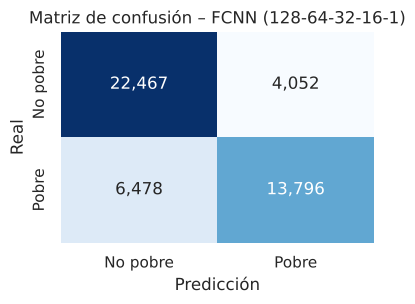

In [20]:
def construir_fcnn(n_entradas, unidades=(128, 64, 32, 16), dropout=(0.30, 0.30, 0.20, 0.10), l2=1e-5, lr=1e-3):
    entrada = keras.Input(shape=(n_entradas,))
    x = entrada
    for u, d in zip(unidades, dropout):
        x = layers.Dense(u, kernel_regularizer=regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(d)(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    modelo = keras.Model(entrada, salida, name="FCNN_128_64_32_16_1")
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return modelo

keras.utils.set_random_seed(SEMILLA)
fcnn = construir_fcnn(Xs_tr.shape[1])
fcnn.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=4, min_lr=1e-5)]
t0 = time.time()
hist = fcnn.fit(Xs_tr, y_tr, validation_data=(Xs_val, y_val), epochs=150, batch_size=1024,
                callbacks=callbacks, verbose=0)
t_fcnn = time.time() - t0
print(f"Épocas entrenadas: {len(hist.history['loss'])} | tiempo: {t_fcnn:.0f} s")

proba = fcnn.predict(Xs_test, batch_size=4096, verbose=0).ravel()
registrar("FCNN (128-64-32-16-1)", proba, (proba >= 0.5).astype(int), t_fcnn)

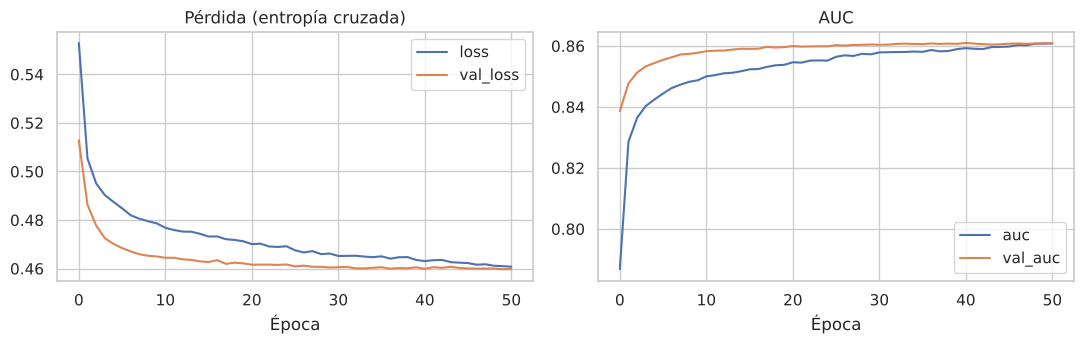

In [21]:
# Curvas de aprendizaje de la FCNN
h = pd.DataFrame(hist.history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Pérdida (entropía cruzada)")
h[["auc", "val_auc"]].plot(ax=ax[1], title="AUC")
for a_ in ax: a_.set_xlabel("Época")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_curvas_fcnn.png"), dpi=300); plt.show()

### 11.2 Random Forest


===== Random Forest =====
              precision    recall  f1-score   support

    No pobre     0.7776    0.8231    0.7997     26519
       Pobre     0.7495    0.6921    0.7196     20274

    accuracy                         0.7664     46793
   macro avg     0.7635    0.7576    0.7597     46793
weighted avg     0.7654    0.7664    0.7650     46793

ROC-AUC: 0.8445 | MCC: 0.5211


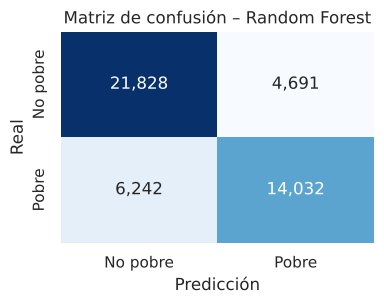

In [22]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=400, random_state=SEMILLA, n_jobs=-1,
                            **mejores["Random Forest"]).fit(Xt_train, y_train)
proba = rf.predict_proba(Xt_test)[:, 1]
registrar("Random Forest", proba, (proba >= 0.5).astype(int), time.time() - t0)

### 11.3 Regresión logística


===== Regresión logística =====
              precision    recall  f1-score   support

    No pobre     0.7680    0.8201    0.7932     26519
       Pobre     0.7417    0.6759    0.7073     20274

    accuracy                         0.7576     46793
   macro avg     0.7549    0.7480    0.7502     46793
weighted avg     0.7566    0.7576    0.7560     46793

ROC-AUC: 0.8343 | MCC: 0.5028


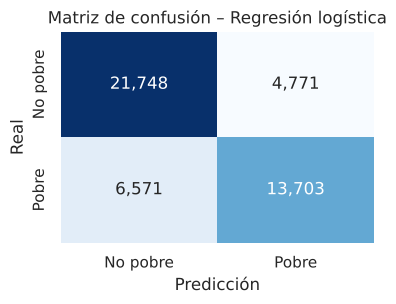

In [23]:
t0 = time.time()
lr_mod = LogisticRegression(max_iter=3000, **mejores["Regresión logística"]).fit(Xt_train, y_train)
proba = lr_mod.predict_proba(Xt_test)[:, 1]
registrar("Regresión logística", proba, (proba >= 0.5).astype(int), time.time() - t0)

### 11.4 Perceptrón multicapa (MLP)


===== Perceptrón multicapa =====
              precision    recall  f1-score   support

    No pobre     0.7861    0.8290    0.8070     26519
       Pobre     0.7592    0.7049    0.7310     20274

    accuracy                         0.7753     46793
   macro avg     0.7726    0.7670    0.7690     46793
weighted avg     0.7744    0.7753    0.7741     46793

ROC-AUC: 0.8541 | MCC: 0.5396


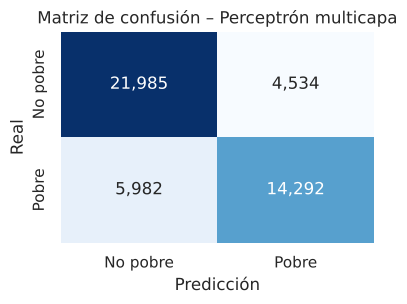

In [24]:
t0 = time.time()
mlp = MLPClassifier(early_stopping=True, max_iter=300, n_iter_no_change=10, random_state=SEMILLA,
                    **mejores["Perceptrón multicapa"]).fit(Xt_train, y_train)
proba = mlp.predict_proba(Xt_test)[:, 1]
registrar("Perceptrón multicapa", proba, (proba >= 0.5).astype(int), time.time() - t0)

### 11.5 Perceptrón simple (clásico) y perceptrón promediado
El perceptrón clásico actualiza los pesos solo cuando se equivoca; si las clases no son linealmente separables (como aquí), los pesos oscilan y el modelo final depende de la última actualización, lo que lo hace **inestable**. El perceptrón promediado conserva la misma regla de aprendizaje, pero devuelve el promedio de los pesos de todas las iteraciones.


===== Perceptrón =====
              precision    recall  f1-score   support

    No pobre     0.7278    0.4148    0.5284     26519
       Pobre     0.5101    0.7971    0.6221     20274

    accuracy                         0.5804     46793
   macro avg     0.6190    0.6059    0.5753     46793
weighted avg     0.6335    0.5804    0.5690     46793

ROC-AUC: 0.6709 | MCC: 0.2245


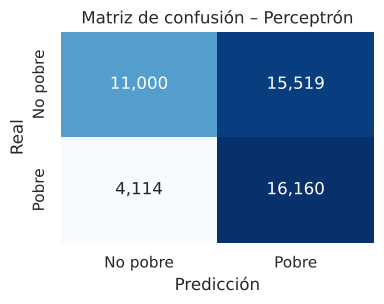

In [25]:
t0 = time.time()
per = Perceptron(random_state=SEMILLA, early_stopping=True, **mejores["Perceptrón"]).fit(Xt_train, y_train)
dec = per.decision_function(Xt_test)           # el perceptrón no estima probabilidades
registrar("Perceptrón", dec, per.predict(Xt_test), time.time() - t0)


===== Perceptrón promediado =====
              precision    recall  f1-score   support

    No pobre     0.7697    0.8089    0.7888     26519
       Pobre     0.7322    0.6834    0.7070     20274

    accuracy                         0.7545     46793
   macro avg     0.7510    0.7462    0.7479     46793
weighted avg     0.7535    0.7545    0.7534     46793

ROC-AUC: 0.8319 | MCC: 0.4971


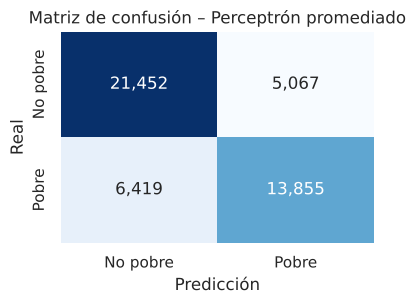

In [26]:
t0 = time.time()
per_avg = SGDClassifier(loss="perceptron", average=True, max_iter=50, tol=1e-4, random_state=SEMILLA,
                        **mejores["Perceptrón promediado"]).fit(Xt_train, y_train)
registrar("Perceptrón promediado", per_avg.decision_function(Xt_test), per_avg.predict(Xt_test), time.time() - t0)

### 11.6 XGBoost (con *early stopping* sobre el conjunto de validación)

Mejor iteración: 706



===== XGBoost =====
              precision    recall  f1-score   support

    No pobre     0.7898    0.8285    0.8087     26519
       Pobre     0.7603    0.7117    0.7352     20274

    accuracy                         0.7779     46793
   macro avg     0.7751    0.7701    0.7719     46793
weighted avg     0.7771    0.7779    0.7769     46793

ROC-AUC: 0.8584 | MCC: 0.5451


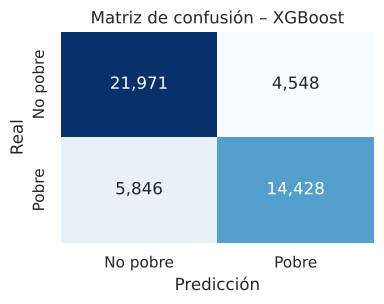

In [27]:
t0 = time.time()
xgb_mod = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="logloss",
                            early_stopping_rounds=50, random_state=SEMILLA, n_jobs=-1,
                            **mejores["XGBoost"])
xgb_mod.fit(Xs_tr, y_tr, eval_set=[(Xs_val, y_val)], verbose=False)
print("Mejor iteración:", xgb_mod.best_iteration)
proba = xgb_mod.predict_proba(Xs_test)[:, 1]
registrar("XGBoost", proba, (proba >= 0.5).astype(int), time.time() - t0)

### 11.7 Gradient Boosting (HistGradientBoostingClassifier)

Iteraciones: 339



===== Gradient Boosting =====
              precision    recall  f1-score   support

    No pobre     0.7895    0.8273    0.8080     26519
       Pobre     0.7591    0.7116    0.7345     20274

    accuracy                         0.7772     46793
   macro avg     0.7743    0.7694    0.7713     46793
weighted avg     0.7763    0.7772    0.7762     46793

ROC-AUC: 0.8575 | MCC: 0.5437


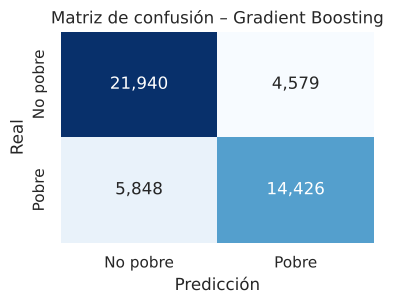

In [28]:
t0 = time.time()
gb = HistGradientBoostingClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.1,
                                    n_iter_no_change=30, random_state=SEMILLA,
                                    **mejores["Gradient Boosting"]).fit(Xt_train, y_train)
print("Iteraciones:", gb.n_iter_)
proba = gb.predict_proba(Xt_test)[:, 1]
registrar("Gradient Boosting", proba, (proba >= 0.5).astype(int), time.time() - t0)

## 12. Comparación de modelos y pruebas estadísticas
* **Tabla de métricas** (precisión, recall y F1 ponderados, como en el flujo original, más métricas de la clase *pobre*, ROC‑AUC y MCC).
* **Intervalos de confianza al 95 %** de la exactitud mediante *bootstrap* (1 000 remuestreos del conjunto de prueba).
* **Prueba de McNemar** (con corrección de continuidad) entre el mejor modelo y cada uno de los demás.

In [29]:
tabla = pd.DataFrame(resultados).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(tabla.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Precision (pobre),Recall (pobre),F1 (pobre),ROC-AUC,MCC,Tiempo (s)
0,XGBoost,0.7779,0.7771,0.7779,0.7769,0.7603,0.7117,0.7352,0.8584,0.5451,26.6518
1,Gradient Boosting,0.7772,0.7763,0.7772,0.7762,0.7591,0.7116,0.7345,0.8575,0.5437,34.3193
2,Perceptrón multicapa,0.7753,0.7744,0.7753,0.7741,0.7592,0.7049,0.7310,0.8541,0.5396,17.5639
3,FCNN (128-64-32-16-1),0.7750,0.7748,0.7750,0.7727,0.7730,0.6805,0.7238,0.8557,0.5383,67.0434
4,Random Forest,0.7664,0.7654,0.7664,0.7650,0.7495,0.6921,0.7196,0.8445,0.5211,234.4823
5,Regresión logística,0.7576,0.7566,0.7576,0.7560,0.7417,0.6759,0.7073,0.8343,0.5028,0.8098
6,Perceptrón promediado,0.7545,0.7535,0.7545,0.7534,0.7322,0.6834,0.7070,0.8319,0.4971,1.6359
7,Perceptrón,0.5804,0.6335,0.5804,0.5690,0.5101,0.7971,0.6221,0.6709,0.2245,0.5397


In [30]:
def ic_bootstrap(y_true, pred, B=1000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    n = len(y_true); acier = (y_true == pred).astype(np.float32); acc = np.empty(B)
    for b in range(B):
        acc[b] = acier[rng.integers(0, n, n)].mean()
    return np.percentile(acc, [2.5, 97.5])

def mcnemar(y_true, p1, p2):
    b = np.sum((p1 == y_true) & (p2 != y_true)); c = np.sum((p1 != y_true) & (p2 == y_true))
    est = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0
    return est, 1 - chi2.cdf(est, df=1)

mejor = tabla.loc[0, "Modelo"]
filas = []
for m in tabla.Modelo:
    lo, hi = ic_bootstrap(y_test, predicciones[m]["pred"])
    est, p = (np.nan, np.nan) if m == mejor else mcnemar(y_test, predicciones[mejor]["pred"], predicciones[m]["pred"])
    filas.append({"Modelo": m, "IC95% inf": lo, "IC95% sup": hi, f"McNemar χ² vs {mejor}": est, "p-valor": p})
tabla_estad = pd.DataFrame(filas)
display(tabla_estad.round(4))

,Modelo,IC95% inf,IC95% sup,McNemar χ² vs XGBoost,p-valor
0,XGBoost,0.7742,0.7819,NaN,NaN
1,Gradient Boosting,0.7733,0.7809,0.6636,0.4153
2,Perceptrón multicapa,0.7716,0.7792,5.2252,0.0223
3,FCNN (128-64-32-16-1),0.7712,0.7789,7.2264,0.0072
4,Random Forest,0.7624,0.7704,83.7269,0.0000
5,Regresión logística,0.7534,0.7613,194.9585,0.0000
6,Perceptrón promediado,0.7506,0.7583,244.6118,0.0000
7,Perceptrón,0.5760,0.5846,4516.5728,0.0000


## 13. Visualizaciones

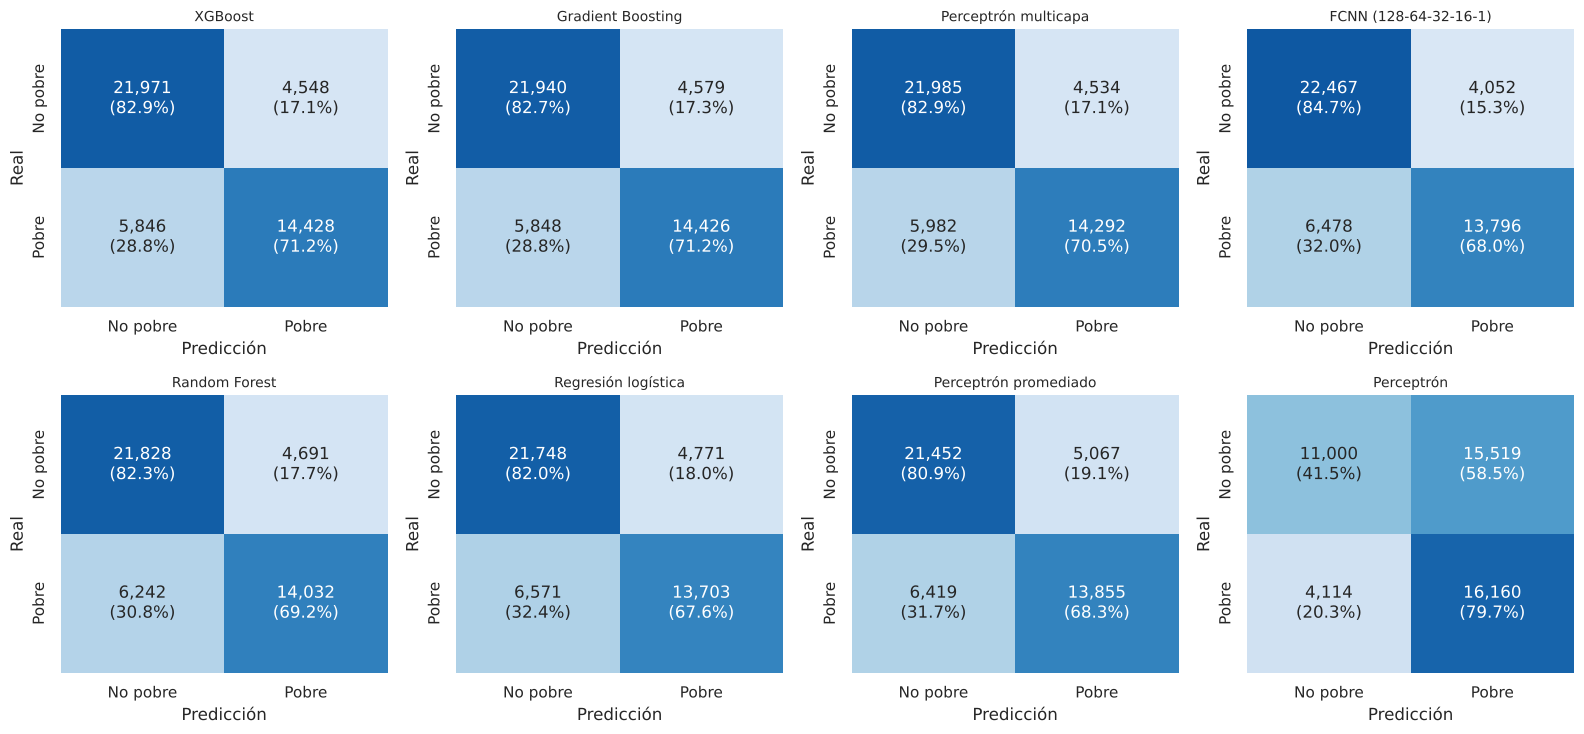

In [31]:
# 13.1 Matrices de confusión normalizadas (por fila) de los siete modelos
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))  # 8 modelos
for a_, m in zip(axes.ravel(), tabla.Modelo):
    cm = confusion_matrix(y_test, predicciones[m]["pred"])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    etiquetas = np.array([[f"{cm[i,j]:,}\n({cmn[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a_,
                xticklabels=["No pobre", "Pobre"], yticklabels=["No pobre", "Pobre"])
    a_.set_title(m, fontsize=10); a_.set_xlabel("Predicción"); a_.set_ylabel("Real")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_matrices_confusion.png"), dpi=300); plt.show()

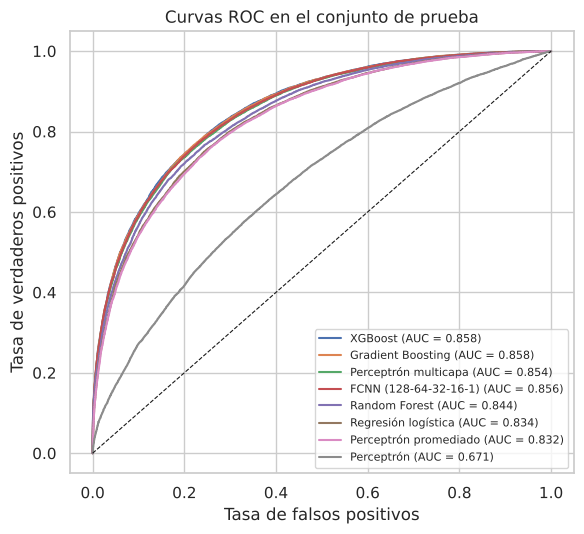

In [32]:
# 13.2 Curvas ROC
plt.figure(figsize=(6, 5.5))
for m in tabla.Modelo:
    fpr, tpr, _ = roc_curve(y_test, predicciones[m]["puntaje"])
    plt.plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_test, predicciones[m]['puntaje']):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.legend(fontsize=8, loc="lower right"); plt.title("Curvas ROC en el conjunto de prueba")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_roc.png"), dpi=300); plt.show()

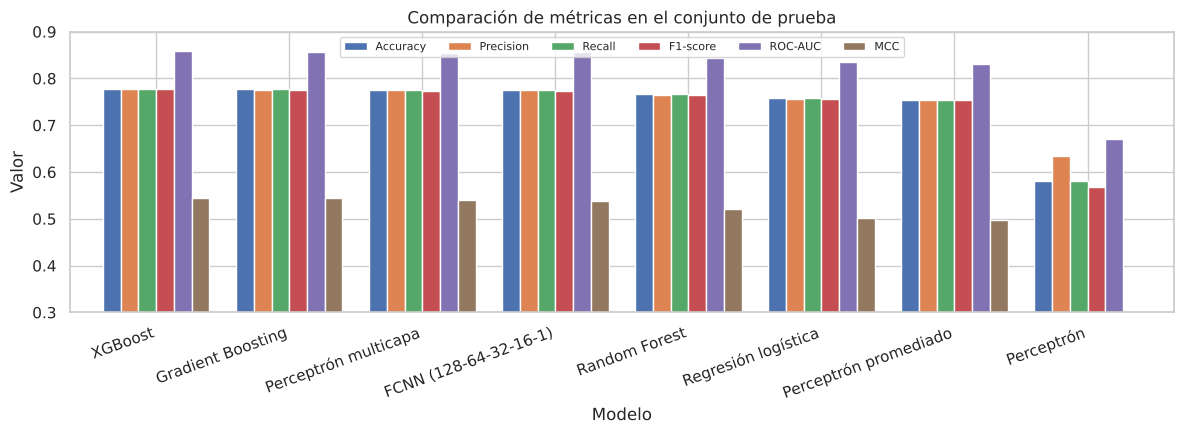

In [33]:
# 13.3 Comparación de métricas
met = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "MCC"]
tabla.set_index("Modelo")[met].plot(kind="bar", figsize=(12, 4.5), width=0.8)
plt.ylim(0.3, 0.9); plt.ylabel("Valor"); plt.xticks(rotation=20, ha="right")
plt.legend(ncol=6, fontsize=8, loc="upper center"); plt.title("Comparación de métricas en el conjunto de prueba")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_metricas.png"), dpi=300); plt.show()

## 14. Estudio de ablación: efecto de cada mejora
Se compara, **sobre la misma partición**, el efecto acumulado de (a) imputar en lugar de eliminar filas, (b) escalar y (c) añadir la ingeniería de características. Se usan la regresión logística, los perceptrones y XGBoost con hiperparámetros fijos (por defecto) para aislar el efecto del preprocesamiento.

También se muestran los resultados registrados en el **notebook original** (partición aleatoria no estratificada, sin escalado y con hiperparámetros por defecto) como referencia.

In [34]:
COLS_FE = ["bano_comp_nulo", "tasa_dependencia", "trab_por_integ", "hacinamiento", "integ_por_bano",
           "inseg_alim_suma", "indice_bienes", "sin_trabajador"]

def prep_config(escalar, usar_fe):
    num = [c for c in NUM if usar_fe or c not in COLS_FE]
    binv = [c for c in BIN if usar_fe or c not in COLS_FE]
    pasos = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(pasos), num),
                              ("bin", SimpleImputer(strategy="most_frequent"), binv),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

configs = {"A. Imputación, sin escalado, sin FE": (False, False),
           "B. + Escalado": (True, False),
           "C. + Escalado + FE (flujo propuesto)": (True, True)}
modelos_abl = {
    "Regresión logística": lambda: LogisticRegression(max_iter=3000),
    "Perceptrón": lambda: Perceptron(random_state=SEMILLA),
    "Perceptrón promediado": lambda: SGDClassifier(loss="perceptron", average=True, random_state=SEMILLA),
    "XGBoost (por defecto)": lambda: xgb.XGBClassifier(tree_method="hist", random_state=SEMILLA, n_jobs=-1)}
filas = []
for cfg, (esc, fe_) in configs.items():
    p = prep_config(esc, fe_).fit(X_train)
    A, B = p.transform(X_train), p.transform(X_test)
    for nm, f in modelos_abl.items():
        pr = f().fit(A, y_train).predict(B)
        filas.append({"Configuración": cfg, "Modelo": nm, "Accuracy": accuracy_score(y_test, pr),
                      "F1-score": f1_score(y_test, pr, average="weighted")})
ablacion = pd.DataFrame(filas).pivot(index="Configuración", columns="Modelo", values="Accuracy")
display(ablacion.round(4))

Modelo,Perceptrón,Perceptrón promediado,Regresión logística,XGBoost (por defecto)
Configuración,,,,
"A. Imputación, sin escalado, sin FE",0.7516,0.7478,0.7549,0.7739
B. + Escalado,0.6785,0.7558,0.7549,0.7739
C. + Escalado + FE (flujo propuesto),0.6745,0.7564,0.7576,0.7744


In [35]:
# Resultados reportados por el notebook original (referencia; partición distinta, n_prueba = 45 626)
original = pd.DataFrame({
    "Modelo": ["Random Forest", "Red neuronal full connected (128-64-32)", "Perceptrón multicapa (100)",
               "Regresión logística", "Perceptrón simple"],
    "Accuracy": [0.7661, 0.7653, 0.7629, 0.7507, 0.6525],
    "F1-score": [0.7644, 0.7651, 0.7572, 0.7492, 0.6431]})
display(original)

,Modelo,Accuracy,F1-score
0,Random Forest,0.7661,0.7644
1,Red neuronal full connected (128-64-32),0.7653,0.7651
2,Perceptrón multicapa (100),0.7629,0.7572
3,Regresión logística,0.7507,0.7492
4,Perceptrón simple,0.6525,0.6431


## 15. Interpretabilidad: importancia por permutación
Se mide la disminución de la exactitud del mejor modelo de árboles al permutar aleatoriamente cada variable **original** (las variables derivadas se recalculan después de permutar). Se usa una submuestra de 15 000 hogares del conjunto de prueba y 5 repeticiones.

Modelo analizado: XGBoost


,media,desv
tot_integ,0.1060,0.0021
prog_soc_porcent,0.0687,0.0015
tot_trab,0.0420,0.0017
rur_urb,0.0282,0.0008
entidad,0.0192,0.0014
escolaridad_educacion_jh,0.0141,0.0011
anio,0.0110,0.0007
edad_jefe,0.0064,0.0013
auto_camioneta_van,0.0061,0.0014
bano_comp,0.0048,0.0010


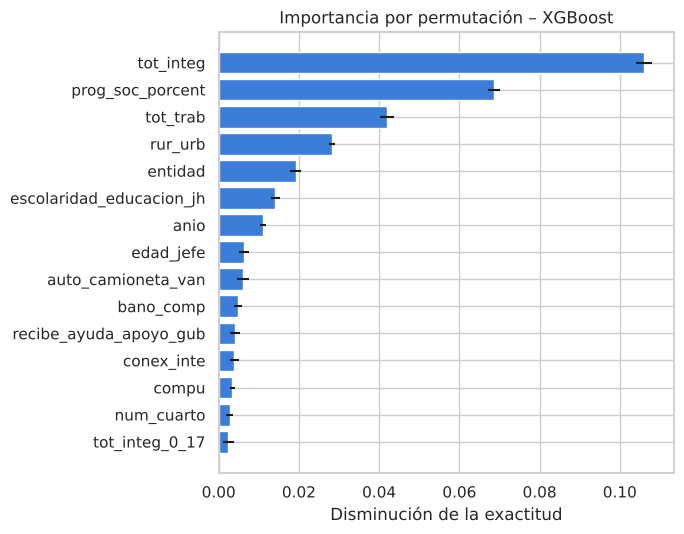

In [36]:
def importancia_permutacion(predecir, Xr, yr, n_rep=5, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    base = accuracy_score(yr, predecir(ingenieria_caracteristicas(Xr)))
    imp = {}
    for c in Xr.columns:
        caidas = []
        for _ in range(n_rep):
            Xp = Xr.copy(); Xp[c] = rng.permutation(Xp[c].values)
            caidas.append(base - accuracy_score(yr, predecir(ingenieria_caracteristicas(Xp))))
        imp[c] = (np.mean(caidas), np.std(caidas))
    return pd.DataFrame(imp, index=["media", "desv"]).T.sort_values("media", ascending=False)

modelos_arbol = {"XGBoost": lambda Z: xgb_mod.predict(pre_tr.transform(Z)),
                 "Gradient Boosting": lambda Z: gb.predict(pre.transform(Z)),
                 "Random Forest": lambda Z: rf.predict(pre.transform(Z))}
mejor_arbol = tabla[tabla.Modelo.isin(modelos_arbol)].iloc[0].Modelo
print("Modelo analizado:", mejor_arbol)

idx_imp, _ = train_test_split(np.arange(len(y_test)), train_size=15_000, stratify=y_test, random_state=SEMILLA)
Xr_test = X_test.iloc[idx_imp][X_raw.columns]
imp = importancia_permutacion(modelos_arbol[mejor_arbol], Xr_test, y_test[idx_imp])
display(imp.head(15).round(4))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(7, 5.5))
plt.barh(top.index, top["media"], xerr=top["desv"], color="#3B7DD8")
plt.xlabel("Disminución de la exactitud"); plt.title(f"Importancia por permutación – {mejor_arbol}")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_importancia.png"), dpi=300); plt.show()

### 15.1 Análisis de sensibilidad: variable `prog_soc_porcent`
`prog_soc_porcent` es la proporción del ingreso del hogar que proviene de programas sociales; al estar expresada respecto del ingreso, contiene información **indirecta** del ingreso. Para cuantificar su efecto se reentrena XGBoost (mismos hiperparámetros y *early stopping*) excluyéndola.

In [37]:
sin_ps = [c for c in X.columns if c != "prog_soc_porcent"]
NUM_bak = NUM.copy()
NUM = [c for c in NUM if c != "prog_soc_porcent"]
pre_s = crear_preprocesador().fit(X_tr[sin_ps])
NUM = NUM_bak
xgb_s = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="logloss", early_stopping_rounds=50,
                          random_state=SEMILLA, n_jobs=-1, **mejores["XGBoost"])
xgb_s.fit(pre_s.transform(X_tr[sin_ps]), y_tr, eval_set=[(pre_s.transform(X_val[sin_ps]), y_val)], verbose=False)
p_s = xgb_s.predict_proba(pre_s.transform(X_test[sin_ps]))[:, 1]
sens = pd.DataFrame({"Variante": ["XGBoost (todas las variables)", "XGBoost sin prog_soc_porcent"],
                     "Accuracy": [accuracy_score(y_test, predicciones["XGBoost"]["pred"]), accuracy_score(y_test, p_s >= 0.5)],
                     "ROC-AUC": [roc_auc_score(y_test, predicciones["XGBoost"]["puntaje"]), roc_auc_score(y_test, p_s)],
                     "MCC": [matthews_corrcoef(y_test, predicciones["XGBoost"]["pred"]), matthews_corrcoef(y_test, p_s >= 0.5)]})
display(sens.round(4))
sens.to_csv(os.path.join(CARPETA_SALIDA, "sensibilidad_prog_soc.csv"), index=False)

,Variante,Accuracy,ROC-AUC,MCC
0,XGBoost (todas las variables),0.7779,0.8584,0.5451
1,XGBoost sin prog_soc_porcent,0.7571,0.8360,0.5028


## 16. Exportación de resultados

In [38]:
tabla.to_csv(os.path.join(CARPETA_SALIDA, "metricas_modelos.csv"), index=False)
tabla_estad.to_csv(os.path.join(CARPETA_SALIDA, "ic_y_mcnemar.csv"), index=False)
ablacion.to_csv(os.path.join(CARPETA_SALIDA, "ablacion.csv"))
imp.to_csv(os.path.join(CARPETA_SALIDA, "importancia_permutacion.csv"))
print("Archivos guardados en:", os.path.abspath(CARPETA_SALIDA))
print(os.listdir(CARPETA_SALIDA))

Archivos guardados en: /home/claude/resultados_pobreza
['ablacion.csv', 'ic_y_mcnemar.csv', 'metricas_modelos.csv', 'sensibilidad_prog_soc.csv', 'importancia_permutacion.csv', 'mejores_hiperparametros.json', 'fig_importancia.png', 'fig_roc.png', 'fig_metricas.png', 'fig_curvas_fcnn.png', 'fig_matrices_confusion.png']


## 17. Conclusiones

**Resultados principales (conjunto de prueba, 46 793 hogares):**

| Modelo | Accuracy | ROC-AUC | MCC |
|---|---|---|---|
| XGBoost | 0.7779 | 0.8584 | 0.5451 |
| Gradient Boosting | 0.7772 | 0.8575 | 0.5437 |
| Perceptrón multicapa | 0.7753 | 0.8541 | 0.5396 |
| FCNN (128-64-32-16-1) | 0.7750 | 0.8557 | 0.5383 |
| Random Forest | 0.7664 | 0.8445 | 0.5211 |
| Regresión logística | 0.7576 | 0.8343 | 0.5028 |
| Perceptrón promediado | 0.7545 | 0.8319 | 0.4971 |
| Perceptrón | 0.5804 | 0.6709 | 0.2245 |

1. **XGBoost** obtuvo el mejor desempeño (0.7779); la diferencia con **Gradient Boosting** (0.7772) no es estadísticamente significativa (McNemar, p = 0.415).
2. El **perceptrón multicapa** (0.7753) y la **FCNN 128‑64‑32‑16‑1** (0.7750) quedan muy cerca (< 0.3 puntos porcentuales), aunque la diferencia con XGBoost sí es significativa.
3. Respecto al flujo original (mejor exactitud 0.7661, Random Forest), la mejor exactitud sube a 0.7779. El MLP (+1.24 p. p.), la red totalmente conectada (+0.97 p. p.) y la regresión logística (+0.69 p. p.) mejoran; Random Forest se mantiene igual.
4. El **perceptrón clásico es inestable** (0.708 en validación cruzada vs. 0.5804 en prueba); el **perceptrón promediado** resuelve el problema (0.7545).
5. La ingeniería de características aporta poco (+0.05 a +0.28 p. p.); la mayor ganancia viene del ajuste de hiperparámetros, la regularización y los modelos de *boosting*.
6. **Advertencia:** `prog_soc_porcent` contiene información indirecta del ingreso. Sin ella, XGBoost baja de 0.7779 a 0.7571. Si el modelo se usará sin ninguna información del ingreso, esa es la cifra de referencia.

**Trabajo futuro:** validación temporal (entrenar con 2016–2018 y evaluar con 2020), uso de factores de expansión y ajuste del umbral de decisión para reducir falsos negativos; modelar `plp_e` con técnicas para clases desbalanceadas.
